# Notebook 4: Programming a leak valve through its RS232 port

*Python for Instrumentation and Laboratory Experiments, Pr. T. Angot*

**Task:** write a Python program that controls a leak valve through its RS232 port: test the device status, check the valve position, set it to a chosen position, hold it there for a certain time, and finally close it. Then document how the valve works and how the program works.

We did not have access to the valve, so the program is written from the manual (*VAT Series 590, Installation, Operating & Maintenance Instructions*, file `programming_a_leak_valve.pdf`). To test it anyway, section 5 runs it on a small **simulated valve** that answers like the real one according to the manual.

## 1. How the valve works

The **VAT Series 590** is a *variable leak valve* (DN 16) with an integrated controller. It is used to let a small, controlled gas flow into a vacuum chamber.

- **Mechanism.** A valve plate acts as a throttling element: it changes the conductance of the opening, so the gas flow. It is moved by a **stepper motor**, which allows very precise positioning: the full stroke is divided into **100 000 steps** (position 0 = closed, 100 000 = fully open). Going from closed to open takes about 3.5 s. A stopper prevents over-tightening of the seat when the valve closes.
- **Two control modes.**
  - **Position control:** we give a position setpoint and the controller moves the plate there. This is what we use here.
  - **Pressure control:** a pressure gauge is connected to the SENSOR input (0-10 V). The controller reads the pressure and moves the plate by itself to reach a pressure setpoint. This needs a setup procedure first.
  - The manual notes that for the same position, the pressure is slightly higher if the position is reached by opening than by closing (hysteresis), so it is better to always approach a position from the same side.
- **Local / remote.** The valve can be operated locally (service port, VAT software or Service Box) or remotely through the RS232 interface. RS232 commands are refused in local mode (error `E:000080`).
- **Safety.** The digital inputs OPEN / CLOSE (*interlocks*) have priority over all RS232 commands. At power up, the valve synchronizes its motor (position unknown, `A:` returns 999999 during this time) and then closes. During a power failure it stays where it is.

## 2. How to communicate with it

**Port settings** (factory default, can be changed in the setup): **9600 baud, 7 data bits, even parity, 1 stop bit**, i.e. *7E1*. This is different from the Keithley (8N1), so the settings must be changed in `serial.Serial`.

**Syntax** (manual, §4.7.1):
- commands and values are **case sensitive**,
- each command ends with **CR LF** (`\r\n`),
- the valve sends an **acknowledgement** within 10 ms, and we must **wait for it before sending the next command**,
- if a command is refused, the answer is an error `E:xxxxxx`.

**Commands used:**

| Command | Function | Answer |
|---|---|---|
| `i:30` | device status | `i:30abcdefgh` (a = access mode, b = control mode, d = warning, h = simulation) |
| `A:` | read the current position | `A:aaaaaa` (0 - 100000, 999999 = unknown) |
| `R:aaaaaa` | position control, setpoint `aaaaaa` (6 digits) | `R:` |
| `H:` | hold: stop the valve at its current position | `H:` |
| `C:` | close the valve | `C:` |
| `O:` | open the valve | `O:` |
| `i:51` | warnings (service request, etc.) | `i:51abcdefgh` |
| `i:50` | fatal error code | `i:50abc` |

**Status `i:30`:** a = access mode (0 local, 1 remote, 2 locked remote); b = control mode (1 synchronization, 2 position control, 3 closed, 4 open, 5 pressure control, 6 hold, 8/9 interlock open/closed, C power failure, D safety mode, E fatal error).

## 3. Libraries

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import serial
import serial.tools.list_ports as port_list

## 4. The program

### 4.1 Settings and tables from the manual

In [2]:
VALVE_SETTINGS = dict(baudrate=9600, bytesize=serial.SEVENBITS, parity=serial.PARITY_EVEN,
                      stopbits=serial.STOPBITS_ONE, timeout=1)

ACCESS_MODES = {'0': 'local', '1': 'remote', '2': 'locked remote'}
CONTROL_MODES = {'0': 'initialization', '1': 'synchronization', '2': 'position control', '3': 'closed',
                 '4': 'open', '5': 'pressure control', '6': 'hold', '8': 'interlock open',
                 '9': 'interlock closed', 'C': 'power failure', 'D': 'safety mode', 'E': 'fatal error'}
ERRORS = {'E:000001': 'parity error', 'E:000002': 'input buffer overflow', 'E:000003': 'framing error',
          'E:000004': 'overrun', 'E:000010': 'CR or LF missing', 'E:000011': ': missing',
          'E:000012': 'invalid number of characters', 'E:000023': 'invalid value',
          'E:000030': 'value out of range', 'E:000041': 'command not applicable for this hardware',
          'E:000060': 'ZERO disabled', 'E:000080': 'command not accepted: valve in local operation',
          'E:000081': 'command not accepted: service interface locked',
          'E:000082': 'command not accepted: synchronization, interlock, safety mode or fatal error',
          'E:000089': 'not accepted in calibration and test mode'}

POSITION_MAX = 100000    # fully open
UNKNOWN_POSITION = 999999

### 4.2 Basic functions

`send()` is the only function that talks to the port. It sends one command, waits for the acknowledgement and checks it, as required by the manual. If something goes wrong it raises a `ValveError` with a readable message, which stops the sequence instead of continuing blindly.

In [3]:
class ValveError(Exception):
    pass

def send(ser, cmd):
    ser.reset_input_buffer()
    ser.write((cmd + "\r\n").encode("ascii"))
    reply = ser.readline().decode("ascii", errors="replace").strip()
    if reply == "":
        raise ValveError(f"no answer to {cmd!r} (cable, port or settings?)")
    if reply.startswith("E:"):
        raise ValveError(f"{cmd!r} refused: {reply}, {ERRORS.get(reply, 'unknown error')}")
    # a question (i:xx, A:) is answered by the same command followed by the value,
    # an order (R:xxxxxx, H:, C:, O:) only by its first two characters
    expected = cmd if cmd.startswith("i:") or cmd == "A:" else cmd[:2]
    if not reply.startswith(expected):
        raise ValveError(f"unexpected answer {reply!r} to {cmd!r}")
    return reply

def get_status(ser):
    s = send(ser, "i:30")[4:]          # 'abcdefgh'
    return {'access': ACCESS_MODES.get(s[0], s[0]),
            'mode': CONTROL_MODES.get(s[1], s[1]),
            'warning': s[3] == '1',
            'simulation': s[7] == '1'}

def get_position(ser):
    p = int(send(ser, "A:")[2:])
    return None if p == UNKNOWN_POSITION else p

def set_position(ser, position):
    if not 0 <= position <= POSITION_MAX:
        raise ValueError(f"position must be between 0 and {POSITION_MAX}, not {position}")
    send(ser, f"R:{int(position):06d}")

def hold(ser):
    send(ser, "H:")

def close_valve(ser):
    send(ser, "C:")

### 4.3 The complete sequence

1. **Status:** the valve must be in remote mode and in a normal state (no interlock, safety mode or fatal error). Warnings are read and printed.
2. **Position:** read the current position. If it is unknown (synchronization after power up), wait until it is known.
3. **Set the position** and follow the movement until the valve is within `tolerance` steps of the setpoint.
4. **Hold** the position (`H:`) for `hold_time` seconds, reading the position regularly to check that it does not move.
5. **Close** the valve and check that it is closed.

The closing is in a `finally` block: even if an error happens or the program is stopped by hand during steps 3-4, the program still tries to close the valve, which is the safe state for a vacuum chamber.
Every position read is stored in `log` (time, position, mode) to plot it afterwards.

In [4]:
def wait_for_position(ser, target, log, tolerance=100, timeout=30, poll=0.5, t0=0.0,
                      clock=time.time, wait=time.sleep):
    start = clock()
    while True:
        p = get_position(ser)
        log.append((clock() - t0, p, get_status(ser)['mode']))
        if p is not None and abs(p - target) <= tolerance:
            return p
        if clock() - start > timeout:
            raise ValveError(f"position {target} not reached after {timeout} s (last position: {p})")
        wait(poll)

def run_sequence(ser, position, hold_time, tolerance=100, poll=0.5, clock=time.time, wait=time.sleep):
    log = []
    t0 = clock()

    # 1. status
    status = get_status(ser)
    print("status:", status)
    if status['access'] == 'local':
        raise ValveError("the valve is in local operation, RS232 commands would be refused")
    if status['mode'] in ('interlock open', 'interlock closed', 'power failure', 'safety mode', 'fatal error'):
        raise ValveError(f"the valve is not ready: {status['mode']}")
    if status['warning']:
        print("warning present:", send(ser, "i:51"))

    # 2. current position (unknown during synchronization)
    p = get_position(ser)
    while p is None:
        if clock() - t0 > 30:
            raise ValveError("position still unknown after 30 s")
        print("synchronization in progress, waiting...")
        wait(1)
        p = get_position(ser)
    print(f"initial position: {p} ({100*p/POSITION_MAX:.1f} % open)")

    try:
        # 3. go to the requested position
        set_position(ser, position)
        p = wait_for_position(ser, position, log, tolerance, poll=poll, t0=t0, clock=clock, wait=wait)
        print(f"t = {clock()-t0:5.1f} s: position {p} reached")

        # 4. hold it
        hold(ser)
        print(f"t = {clock()-t0:5.1f} s: hold for {hold_time} s, mode = {get_status(ser)['mode']}")
        t_end = clock() + hold_time
        while clock() < t_end:
            wait(min(poll, t_end - clock()))
            log.append((clock() - t0, get_position(ser), get_status(ser)['mode']))
    finally:
        # 5. close, whatever happened before
        print(f"t = {clock()-t0:5.1f} s: closing the valve")
        close_valve(ser)
        wait_for_position(ser, 0, log, tolerance=0, poll=poll, t0=t0, clock=clock, wait=wait)
        print(f"t = {clock()-t0:5.1f} s: valve closed, mode = {get_status(ser)['mode']}")
    return log

### 4.4 Use with the real valve

Not executed: we did not have the valve. The port name must be read from the list of ports, and the position and hold time can be chosen freely (here 30 % open during 60 s).

In [ ]:
for p in port_list.comports():
    print(p)

serial_address = "COM4"   # to adapt, from the list above

with serial.Serial(serial_address, **VALVE_SETTINGS) as ser:
    log = run_sequence(ser, position=30000, hold_time=60)

## 5. Test with a simulated valve

The class below imitates the valve as seen through `pyserial` (`write`, `readline`, `reset_input_buffer`), following the manual: same commands, same answers, same error codes, a plate that moves at 100 000 steps per 3.5 s. A virtual clock replaces `time.time` / `time.sleep`, so the test runs instantly.

⚠️ This is **not** the real valve: it only checks that the program sends correct commands, reads the answers correctly and reacts properly to errors.

In [5]:
class VirtualClock:
    def __init__(self):
        self.now = 0.0
    def time(self):
        return self.now
    def sleep(self, s):
        self.now += s

class FakeVAT590:
    speed = POSITION_MAX/3.5     # steps per second

    def __init__(self, clock, access='1'):
        self.clock = clock
        self.access = access     # '0' local, '1' remote
        self.mode = '3'          # closed
        self.position = 0.0
        self.target = 0.0
        self.last = clock.time()
        self.reply = b""

    def _move(self):
        now = self.clock.time()
        step = self.speed*(now - self.last)
        self.last = now
        if abs(self.target - self.position) <= step:
            self.position = self.target
        else:
            self.position += step*np.sign(self.target - self.position)

    def _answer(self, cmd):
        if cmd in ("i:30", "i:51", "i:50", "A:"):
            if cmd == "i:30":
                return f"i:30{self.access}{self.mode}000000"
            if cmd == "i:51":
                return "i:5100000000"
            if cmd == "i:50":
                return "i:50000"
            return f"A:{int(round(self.position)):06d}"
        if ":" not in cmd:
            return "E:000011"
        if self.access == '0':
            return "E:000080"
        if cmd == "C:":
            self.target, self.mode = 0, '3'
        elif cmd == "O:":
            self.target, self.mode = POSITION_MAX, '4'
        elif cmd == "H:":
            self.target, self.mode = self.position, '6'
        elif cmd.startswith("R:"):
            value = cmd[2:]
            if len(value) != 6 or not value.isdigit():
                return "E:000012"
            if int(value) > POSITION_MAX:
                return "E:000030"
            self.target, self.mode = int(value), '2'
        else:
            return "E:000023"
        return cmd[:2]

    def write(self, data):
        self.clock.sleep(0.01)                     # answer within 10 ms
        self._move()
        text = data.decode("ascii")
        if not text.endswith("\r\n"):
            self.reply = b"E:000010\r\n"
        else:
            self.reply = (self._answer(text[:-2]) + "\r\n").encode("ascii")
        return len(data)

    def readline(self):
        r, self.reply = self.reply, b""
        return r

    def reset_input_buffer(self):
        self.reply = b""

### 5.1 Normal sequence: 30 % open during 60 s, then closed

status: {'access': 'remote', 'mode': 'closed', 'warning': False, 'simulation': False}
initial position: 0 (0.0 % open)
t =   1.1 s: position 30000 reached
t =   1.1 s: hold for 60 s, mode = hold
t =  61.1 s: closing the valve
t =  62.2 s: valve closed, mode = closed


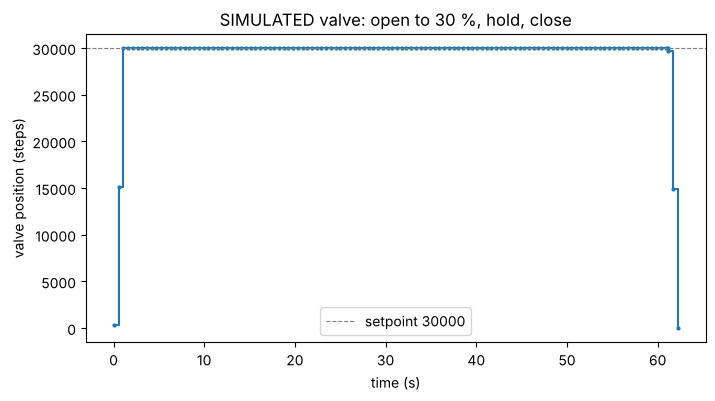

position during the hold: min 30000 max 30000


In [6]:
clock = VirtualClock()
valve = FakeVAT590(clock)
log = run_sequence(valve, position=30000, hold_time=60, clock=clock.time, wait=clock.sleep)

t_log = np.array([row[0] for row in log])
p_log = np.array([row[1] for row in log])
plt.figure(figsize=(8, 4))
plt.step(t_log, p_log, where='post', marker='.', ms=4)
plt.axhline(30000, color='gray', ls='--', lw=0.8, label='setpoint 30000')
plt.xlabel("time (s)")
plt.ylabel("valve position (steps)")
plt.title("SIMULATED valve: open to 30 %, hold, close")
plt.legend()
plt.show()

hold_positions = [p for t, p, mode in log if mode == 'hold']
print("position during the hold: min", min(hold_positions), "max", max(hold_positions))

The valve reaches 30 000 steps in about 1 s (30 % of the 3.5 s full stroke), stays there during the 60 s hold, then closes. Each point is one reading of `A:`.

### 5.2 Error handling

1. A position out of range is refused by `set_position` before anything is sent.
2. If the command is sent anyway, the valve itself refuses it (`E:000030`) and `send` turns that into a readable error.
3. If the valve is in local operation, the sequence stops at the status check, before any movement.

In [7]:
clock = VirtualClock()
valve = FakeVAT590(clock)

try:
    set_position(valve, 150000)
except ValueError as e:
    print("1.", e)

try:
    send(valve, "R:150000")
except ValveError as e:
    print("2.", e)

local_valve = FakeVAT590(clock, access='0')
try:
    run_sequence(local_valve, position=30000, hold_time=60, clock=clock.time, wait=clock.sleep)
except ValveError as e:
    print("3.", e)

1. position must be between 0 and 100000, not 150000
2. 'R:150000' refused: E:000030, value out of range
status: {'access': 'local', 'mode': 'closed', 'warning': False, 'simulation': False}
3. the valve is in local operation, RS232 commands would be refused


## 6. Conclusion

- The VAT 590 leak valve is driven by a stepper motor (100 000 steps over the full stroke) and is controlled through RS232 with short text commands (`i:30`, `A:`, `R:`, `H:`, `C:`), with port settings 9600 baud 7E1 and CR LF at the end of each command.
- The program follows the manual: one command at a time, waiting for and checking each acknowledgement, translating the error codes, refusing out-of-range positions, and always closing the valve at the end, even after an error.
- Tested on a simulated valve, the sequence status → position → 30 % open → hold 60 s → close works, and the three error cases are handled.
- With the real valve, only `serial_address` should need to be changed. The first thing to check would be the port settings (7E1, in case they were changed in the valve setup) and that the valve is in remote mode.